In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Please enable a GPU in Google Colab.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: NVIDIA L4


In [ ]:
import math
import torch

torch.manual_seed(42)

B = 1       # Batch size
H = 8       # Number of attention heads
N = 2048    # Sequence length
D = 64      # Dimension per attention head

device = "cuda"
dtype = torch.float16

Q = torch.randn(B, H, N, D, device=device, dtype=dtype)
K = torch.randn(B, H, N, D, device=device, dtype=dtype)
V = torch.randn(B, H, N, D, device=device, dtype=dtype)

print("Q shape:", Q.shape)
print("K shape:", K.shape)
print("V shape:", V.shape)

Q shape: torch.Size([1, 8, 2048, 64])
K shape: torch.Size([1, 8, 2048, 64])
V shape: torch.Size([1, 8, 2048, 64])


In [ ]:
def manual_attention(Q, K, V):
    scores = Q @ K.transpose(-2, -1)
    scores = scores / math.sqrt(Q.shape[-1])

    probabilities = torch.softmax(scores, dim=-1)

    output = probabilities @ V
    return output


with torch.inference_mode():
    output_manual = manual_attention(Q, K, V)

print("Manual attention output:", output_manual.shape)

Manual attention output: torch.Size([1, 8, 2048, 64])


In [ ]:
scores = Q @ K.transpose(-2, -1)

In [ ]:
probabilities = torch.softmax(scores, dim=-1)

In [ ]:
output = probabilities @ V

In [ ]:
import torch.nn.functional as F
from torch.nn.attention import sdpa_kernel, SDPBackend

In [ ]:
with torch.inference_mode():
    with sdpa_kernel(SDPBackend.FLASH_ATTENTION):
        output_flash = F.scaled_dot_product_attention(
            Q, K, V
        )

print("FlashAttention output:", output_flash.shape)

FlashAttention output: torch.Size([1, 8, 2048, 64])


In [ ]:
difference = (output_manual - output_flash).abs()

print("Maximum absolute difference:", difference.max().item())
print("Mean absolute difference:", difference.mean().item())

print(
    "Outputs approximately equal:",
    torch.allclose(
        output_manual,
        output_flash,
        atol=1e-2,
        rtol=1e-2
    )
)

Maximum absolute difference: 0.0003662109375
Mean absolute difference: 1.52587890625e-05
Outputs approximately equal: True


In [ ]:
import time


def benchmark(fn, warmup=5, iterations=20):
    with torch.inference_mode():
        for _ in range(warmup):
            fn()

        torch.cuda.synchronize()
        start = time.perf_counter()

        for _ in range(iterations):
            fn()

        torch.cuda.synchronize()
        end = time.perf_counter()

    return (end - start) * 1000 / iterations


def manual_fn():
    return manual_attention(Q, K, V)


def flash_fn():
    with sdpa_kernel(SDPBackend.FLASH_ATTENTION):
        return F.scaled_dot_product_attention(Q, K, V)


manual_ms = benchmark(manual_fn)
flash_ms = benchmark(flash_fn)

print(f"Manual attention: {manual_ms:.3f} ms")
print(f"FlashAttention:   {flash_ms:.3f} ms")
print(f"Speedup:          {manual_ms / flash_ms:.2f}x")

Manual attention: 1.759 ms
FlashAttention:   0.150 ms
Speedup:          11.75x


In [ ]:
def peak_extra_memory(fn):
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

    baseline = torch.cuda.memory_allocated()

    with torch.inference_mode():
        output = fn()
        torch.cuda.synchronize()
        peak = torch.cuda.max_memory_allocated()

    del output
    return (peak - baseline) / (1024 ** 2)


manual_memory = peak_extra_memory(manual_fn)
flash_memory = peak_extra_memory(flash_fn)

print(f"Manual attention: {manual_memory:.2f} MiB")
print(f"FlashAttention:   {flash_memory:.2f} MiB")

Manual attention: 130.00 MiB
FlashAttention:   2.06 MiB


In [ ]:
def sdpa_auto_fn():
    return F.scaled_dot_product_attention(Q, K, V)


auto_ms = benchmark(sdpa_auto_fn)

print(f"Manual attention: {manual_ms:.3f} ms")
print(f"SDPA automatic:   {auto_ms:.3f} ms")
print(f"FlashAttention:   {flash_ms:.3f} ms")

Manual attention: 1.759 ms
SDPA automatic:   0.145 ms
FlashAttention:   0.150 ms


In [ ]:
import pandas as pd

results = []

for seq_len in [512, 1024, 2048, 4096]:
    q = torch.randn(1, 8, seq_len, 64, device="cuda", dtype=torch.float16)
    k = torch.randn_like(q)
    v = torch.randn_like(q)

    def manual_test():
        return manual_attention(q, k, v)

    def flash_test():
        with sdpa_kernel(SDPBackend.FLASH_ATTENTION):
            return F.scaled_dot_product_attention(q, k, v)

    manual_time = benchmark(manual_test, warmup=3, iterations=10)
    flash_time = benchmark(flash_test, warmup=3, iterations=10)

    results.append({
        "Sequence Length": seq_len,
        "Manual (ms)": round(manual_time, 3),
        "FlashAttention (ms)": round(flash_time, 3),
        "Speedup": round(manual_time / flash_time, 2)
    })

    del q, k, v
    torch.cuda.empty_cache()

df = pd.DataFrame(results)
display(df)

,Sequence Length,Manual (ms),FlashAttention (ms),Speedup
0,512,0.090,0.069,1.29
1,1024,0.142,0.068,2.10
2,2048,1.772,0.153,11.61
3,4096,6.734,0.541,12.46


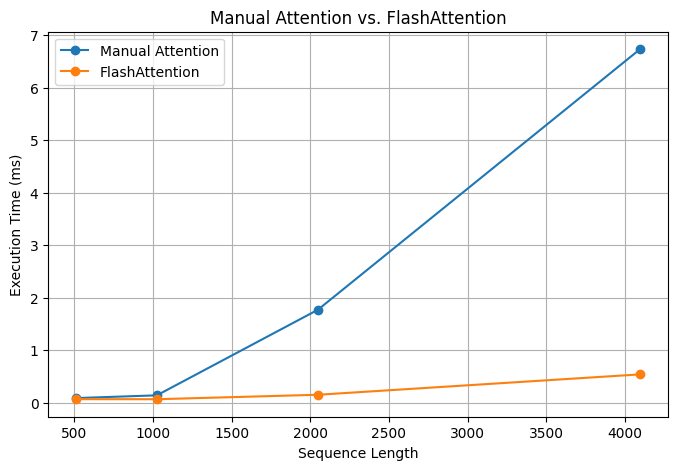

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    df["Sequence Length"],
    df["Manual (ms)"],
    marker="o",
    label="Manual Attention"
)

plt.plot(
    df["Sequence Length"],
    df["FlashAttention (ms)"],
    marker="o",
    label="FlashAttention"
)

plt.xlabel("Sequence Length")
plt.ylabel("Execution Time (ms)")
plt.title("Manual Attention vs. FlashAttention")
plt.legend()
plt.grid(True)
plt.show()

## PYPI

In [ ]:
!pip install flash-attn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.5/8.5 MB 123.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


In [ ]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

model_id = "distilbert/distilgpt2"

tokenizer = AutoTokenizer.from_pretrained(model_id)

model = AutoModelForCausalLM.from_pretrained(
    model_id,
    attn_implementation="eager",
    torch_dtype=torch.float16,
).to("cuda")

inputs = tokenizer(
    "Artificial intelligence is",
    return_tensors="pt",
).to("cuda")

with torch.inference_mode():
    outputs = model.generate(
        **inputs,
        max_new_tokens=30,
        do_sample=False,
    )

print(tokenizer.decode(outputs[0], skip_special_tokens=True))

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

Artificial intelligence is a new technology that is being developed by researchers at the University of California, Berkeley.















In [ ]:
model_flash = AutoModelForCausalLM.from_pretrained(
    model_id,
    attn_implementation="flash_attention_2",
    torch_dtype=torch.float16,
).to("cuda")

with torch.inference_mode():
    outputs_flash = model_flash.generate(
        **inputs,
        max_new_tokens=30,
        do_sample=False,
    )

print(tokenizer.decode(outputs_flash[0], skip_special_tokens=True))

In [ ]:
import time

def benchmark_generation(model, inputs, runs=3):
    with torch.inference_mode():
        # Warm-up
        model.generate(**inputs, max_new_tokens=20, do_sample=False)
        torch.cuda.synchronize()

        start = time.perf_counter()

        for _ in range(runs):
            model.generate(
                **inputs,
                max_new_tokens=30,
                do_sample=False,
            )

        torch.cuda.synchronize()

    return (time.perf_counter() - start) * 1000 / runs


eager_ms = benchmark_generation(model, inputs)
flash_ms = benchmark_generation(model_flash, inputs)

print(f"Eager attention: {eager_ms:.2f} ms")
print(f"FlashAttention: {flash_ms:.2f} ms")
print(f"Speedup: {eager_ms / flash_ms:.2f}x")